Implement and compare the performance of a neural network using different activation
functions (Sigmoid, ReLU, Tanh) on the MNIST dataset. Analyze how each activation
function affects the training process and classification accuracy.  

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Activation: LOGISTIC
Training Time: 35.17 seconds
Accuracy: 96.38 %
Iterations: 30
------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Activation: TANH
Training Time: 46.7 seconds
Accuracy: 96.62 %
Iterations: 30
------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Activation: RELU
Training Time: 33.42 seconds
Accuracy: 96.87 %
Iterations: 30
------------------------------


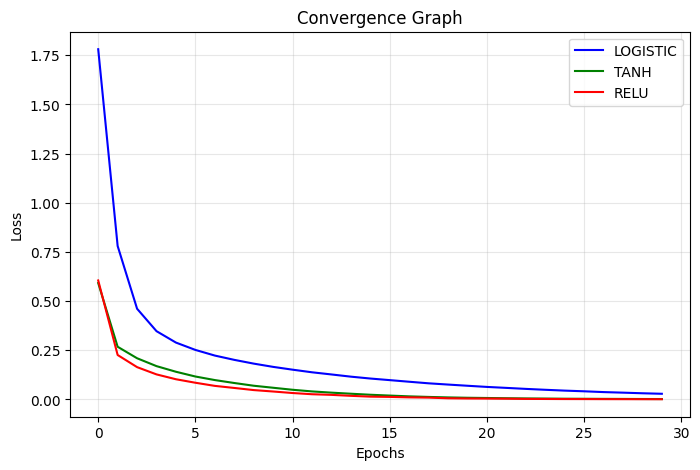

In [1]:

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import time

# Load MNIST dataset
X, y = fetch_openml('mnist_784', version=1, return_X_y=True,
                    as_frame=False, parser='auto')

# Preprocess dataset
# Reduce dataset to 10,000 images
X = X[:30000] / 255.0
y = y[:30000]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Compare activation functions
activations = ['logistic', 'tanh', 'relu']
colors = ['blue', 'green', 'red']

plt.figure(figsize=(8, 5))

for act, color in zip(activations, colors):
    model = MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation=act,
        max_iter=30,
        random_state=42
    )

    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    accuracy = model.score(X_test, y_test) * 100

    print("Activation:", act.upper())
    print("Training Time:", round(training_time, 2), "seconds")
    print("Accuracy:", round(accuracy, 2), "%")
    print("Iterations:", model.n_iter_)
    print("-" * 30)

    plt.plot(model.loss_curve_, label=act.upper(), color=color)

# Plot convergence graph
plt.title("Convergence Graph")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
